<a href="https://colab.research.google.com/github/Devesh07-OGDemiGOD/Quantum-Walk-Simulation/blob/main/Bell_States_All_Four.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1 — Constructing and Verifying All Four Bell States

This notebook extends the provided introductory Qiskit example. It creates all four Bell states, draws each circuit, checks its statevector, and displays measurement histograms using a local simulator.

**Note:** The statevector is calculated before measurement. Measurement histograms show the possible bitstrings, while the statevector also verifies the relative phase.

In [7]:
# Install these packages if they are not already available in your Colab runtime
%pip install -q qiskit qiskit_aer pylatexenc

In [8]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_state_city
import matplotlib.pyplot as plt

sim = AerSimulator()
print("Qiskit setup complete.")

Qiskit setup complete.


## 1. Bell state \(\lvert\Phi^+\rangle = (\lvert00\rangle + \lvert11\rangle)/\sqrt{2}\)

Apply H to qubit 0 to create superposition, then CNOT with qubit 0 as control and qubit 1 as target. This creates correlated outcomes 00 and 11.

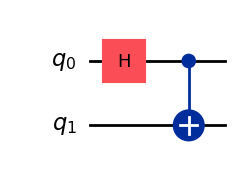

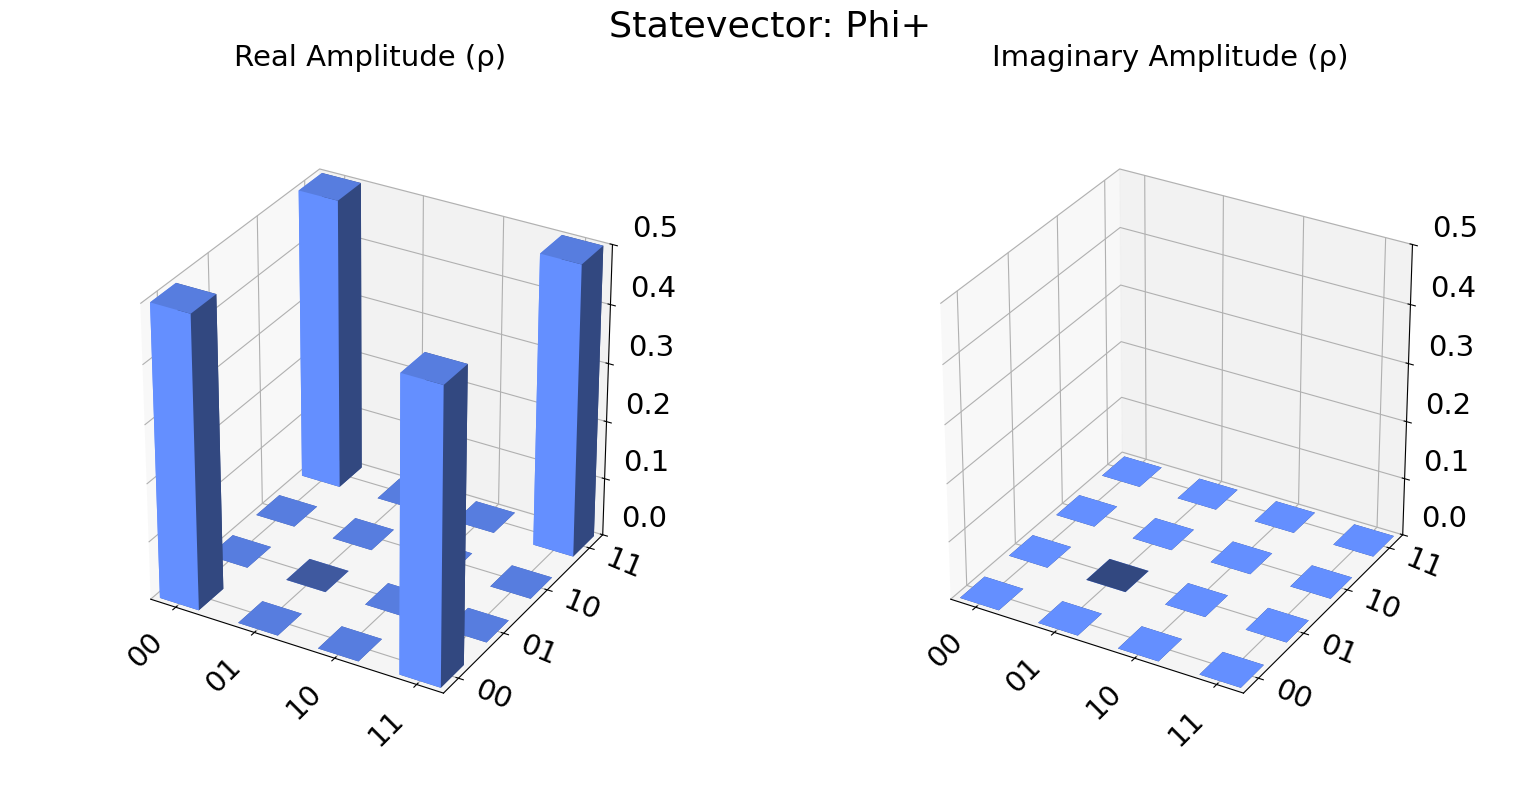

Phi+ measurement counts: {'11': 528, '00': 496}


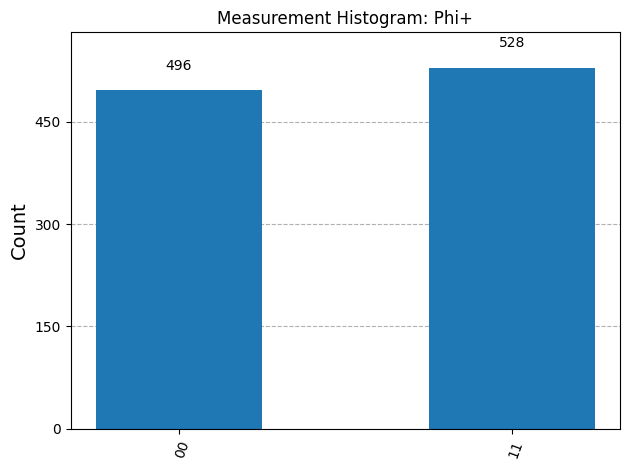

In [9]:
phi_plus = QuantumCircuit(2)
phi_plus.h(0)
phi_plus.cx(0, 1)
display(phi_plus.draw(output="mpl"))

# Verify the ideal statevector before measurement
display(plot_state_city(Statevector.from_instruction(phi_plus).data, title="Statevector: Phi+"))

# Add measurement for histogram
phi_plus_measured = phi_plus.copy()
phi_plus_measured.measure_all()
result = sim.run(transpile(phi_plus_measured, sim), shots=1024).result()
counts_phi_plus = result.get_counts()
print("Phi+ measurement counts:", counts_phi_plus)
display(plot_histogram(counts_phi_plus, title="Measurement Histogram: Phi+"))

## 2. Bell state \(\lvert\Phi^-\rangle = (\lvert00\rangle - \lvert11\rangle)/\sqrt{2}\)

Start with the \(\Phi^+\) circuit and apply Z to qubit 0. The Z gate changes the phase of the \(\lvert1\rangle\) component, producing the minus sign. Its measurement histogram still contains 00 and 11; the statevector confirms the phase difference.

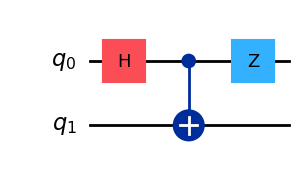

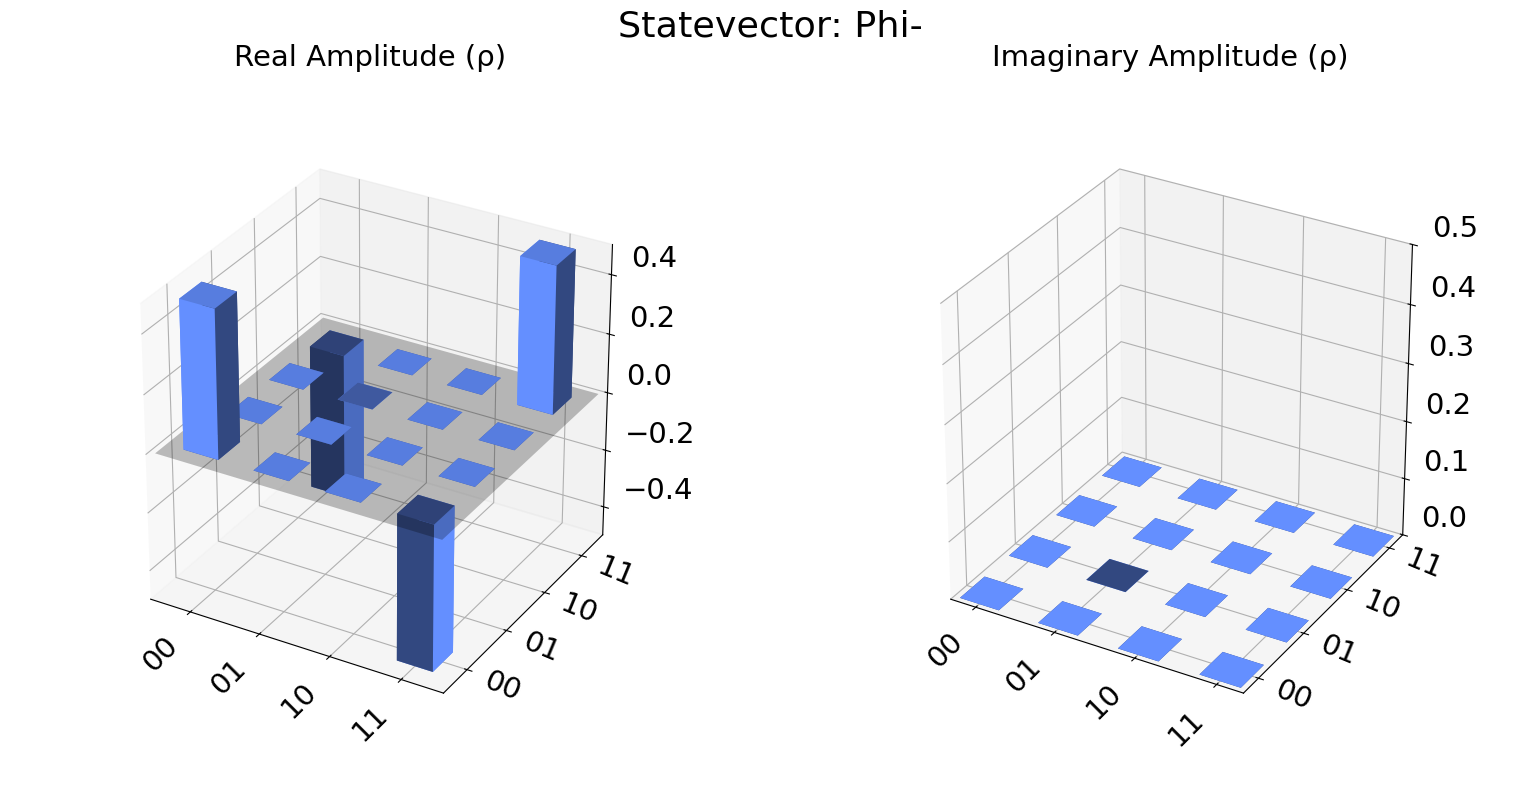

Phi- measurement counts: {'11': 535, '00': 489}


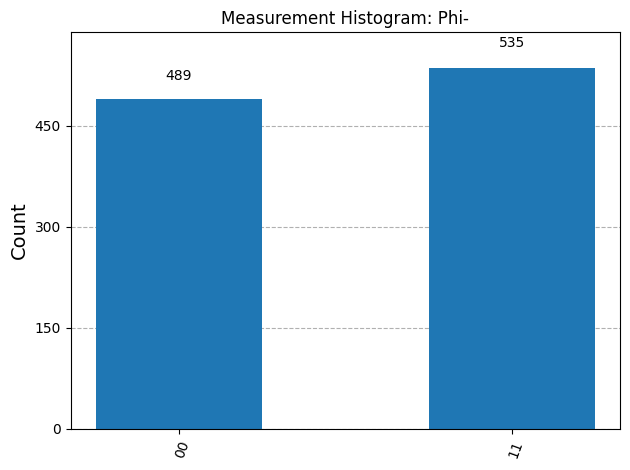

In [10]:
phi_minus = QuantumCircuit(2)
phi_minus.h(0)
phi_minus.cx(0, 1)
phi_minus.z(0)  # Add a relative phase to obtain Phi-
display(phi_minus.draw(output="mpl"))

display(plot_state_city(Statevector.from_instruction(phi_minus).data, title="Statevector: Phi-"))

phi_minus_measured = phi_minus.copy()
phi_minus_measured.measure_all()
result = sim.run(transpile(phi_minus_measured, sim), shots=1024).result()
counts_phi_minus = result.get_counts()
print("Phi- measurement counts:", counts_phi_minus)
display(plot_histogram(counts_phi_minus, title="Measurement Histogram: Phi-"))

## 3. Bell state \(\lvert\Psi^+\rangle = (\lvert01\rangle + \lvert10\rangle)/\sqrt{2}\)

Create \(\Phi^+\), then apply X to qubit 1 to flip the second qubit. The expected measurement outcomes are 01 and 10.

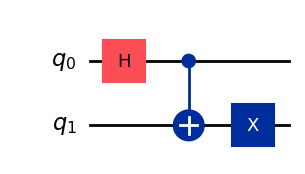

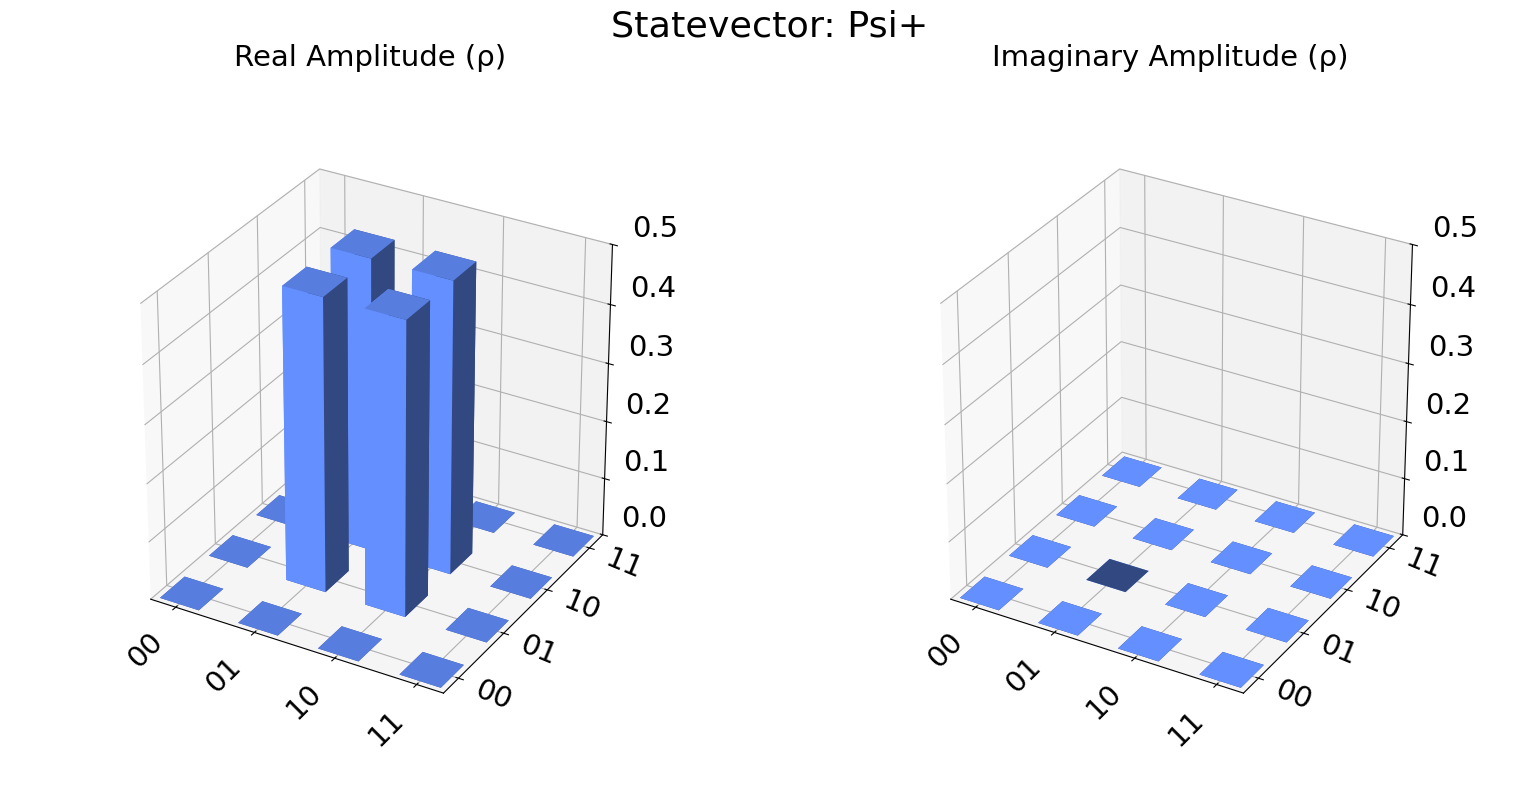

Psi+ measurement counts: {'01': 533, '10': 491}


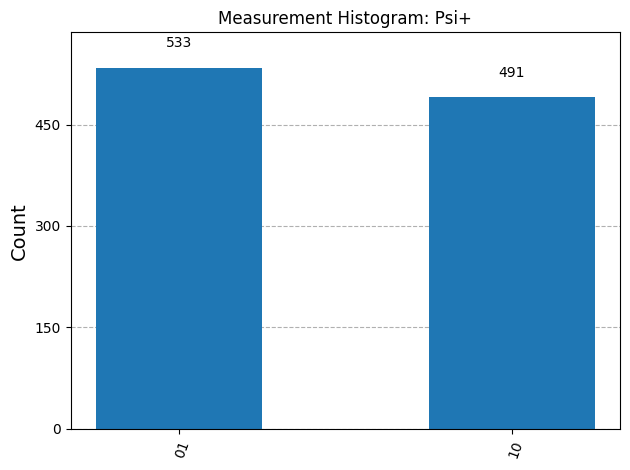

In [11]:
psi_plus = QuantumCircuit(2)
psi_plus.h(0)
psi_plus.cx(0, 1)
psi_plus.x(1)  # Flip qubit 1 to obtain Psi+
display(psi_plus.draw(output="mpl"))

display(plot_state_city(Statevector.from_instruction(psi_plus).data, title="Statevector: Psi+"))

psi_plus_measured = psi_plus.copy()
psi_plus_measured.measure_all()
result = sim.run(transpile(psi_plus_measured, sim), shots=1024).result()
counts_psi_plus = result.get_counts()
print("Psi+ measurement counts:", counts_psi_plus)
display(plot_histogram(counts_psi_plus, title="Measurement Histogram: Psi+"))

## 4. Bell state \(\lvert\Psi^-\rangle = (\lvert01\rangle - \lvert10\rangle)/\sqrt{2}\)

Create \(\Psi^+\), then apply Z to qubit 0 to introduce the relative minus phase. The histogram shows 01 and 10, while the statevector verifies the phase difference from \(\Psi^+\).

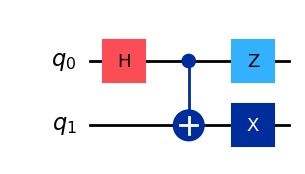

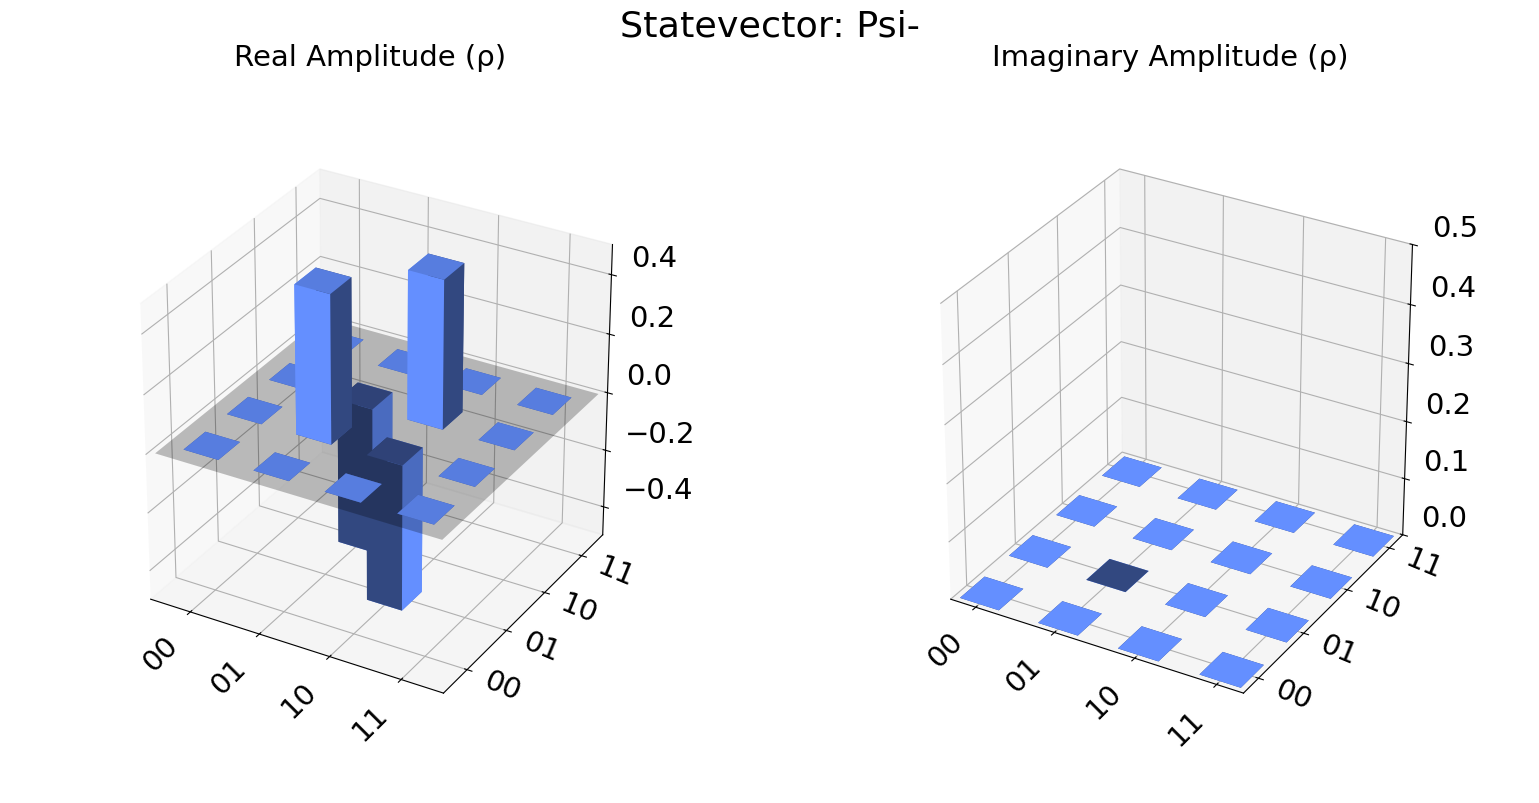

Psi- measurement counts: {'01': 504, '10': 520}


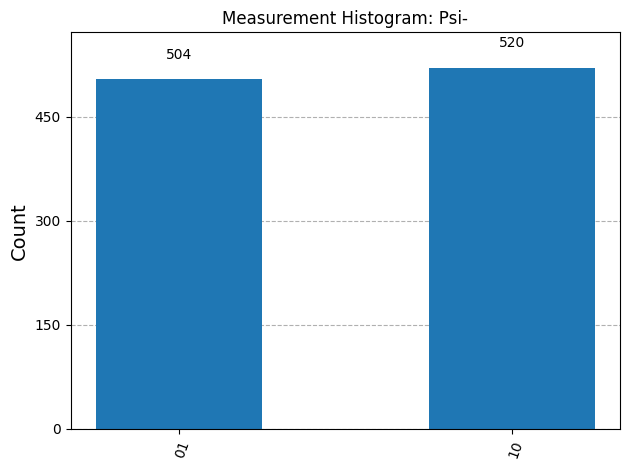

In [12]:
psi_minus = QuantumCircuit(2)
psi_minus.h(0)
psi_minus.cx(0, 1)
psi_minus.x(1)
psi_minus.z(0)  # Add a relative phase to obtain Psi-
display(psi_minus.draw(output="mpl"))

display(plot_state_city(Statevector.from_instruction(psi_minus).data, title="Statevector: Psi-"))

psi_minus_measured = psi_minus.copy()
psi_minus_measured.measure_all()
result = sim.run(transpile(psi_minus_measured, sim), shots=1024).result()
counts_psi_minus = result.get_counts()
print("Psi- measurement counts:", counts_psi_minus)
display(plot_histogram(counts_psi_minus, title="Measurement Histogram: Psi-"))

## Conclusion

All four circuits produce maximally entangled two-qubit Bell states. The \(\Phi\) states give measurement outcomes 00 and 11, while the \(\Psi\) states give 01 and 10. The statevectors are needed to distinguish the plus and minus states because their relative phases do not change these computational-basis histograms.